# Week 11 — Machine learning III: convolutional neural networks

Companion notebook of the eleventh lecture. Sections 0–10 follow chapter 03 of the free online book [*Zero to Mastery Learn PyTorch for Deep Learning*](https://www.learnpytorch.io/03_pytorch_computer_vision/) by Daniel Bourke (code under the MIT license): the **FashionMNIST** images, a plain network as a baseline, and a small **convolutional neural network** (TinyVGG) trained, compared, and evaluated with a confusion matrix. Section 11 adds the lecture's pieces: convolution by hand, what the learned filters see, data augmentation, and class imbalance.

**How to run**: Colab (PyTorch and torchvision are preinstalled; Runtime → Change runtime type → GPU makes training faster) or Anaconda locally (`pip install torch torchvision`), from the [course repository](https://github.com/liwt31/MathModel). Run cells in order with `Shift+Enter`. The data (about 30 MB) are downloaded on first use. On a laptop CPU the whole notebook takes about three minutes, most of it the CNN's training.

**Note.** The exercises here and on the slides are **practice for yourself**, and they are **not** the graded assignments. Problem sets are released separately on Blackboard, with due dates.

![computer vision problems](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-computer-vision-problems.png)

*Computer vision problems: classification (one or many classes), object detection, segmentation. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-computer-vision-problems.png) (Daniel Bourke).*

## 0. Computer vision libraries in PyTorch

| module | what it holds |
|---|---|
| `torchvision` | data sets, model architectures and image transformations for computer vision |
| `torchvision.datasets` | ready-made data sets, among them FashionMNIST |
| `torchvision.models` | well-known network architectures, many with pretrained weights |
| `torchvision.transforms` | functions that turn images into tensors and change them (resize, flip, recolour) |
| `torch.utils.data.Dataset`, `DataLoader` | a data set, and an iterable that serves it in mini-batches |

![the computer vision workflow](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-pytorch-computer-vision-workflow.png)

*The workflow of this notebook. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-pytorch-computer-vision-workflow.png) (Daniel Bourke).*

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
import torchvision
from torchvision import datasets
from torchvision.transforms import ToTensor
try:                                  # optional style file, ships with the course
    plt.style.use("mm.mplstyle")
except OSError:
    pass
plt.rcParams.update({"figure.figsize": (6.4, 4.0), "figure.dpi": 100, "axes.titlesize": 10, "axes.grid": False})
print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}")

PyTorch version: 2.15.0+cpu
torchvision version: 0.29.2+cpu


## 1. Getting a dataset

**FashionMNIST** was published by the online fashion retailer Zalando in 2017: 70,000 greyscale photos of clothing items, 28 × 28 pixels each, in 10 classes, split into 60,000 training and 10,000 test images. `ToTensor()` turns each image into a tensor with values between 0 and 1.

![FashionMNIST examples](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-fashion-mnist-slide.png)

*Examples from FashionMNIST. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-fashion-mnist-slide.png) (Daniel Bourke).*

In [2]:
train_data = datasets.FashionMNIST(root="data", train=True, download=True, transform=ToTensor(), target_transform=None)
test_data = datasets.FashionMNIST(root="data", train=False, download=True, transform=ToTensor())
image, label = train_data[0]
print("image shape:", image.shape, " label:", label)
print(len(train_data.data), len(train_data.targets), len(test_data.data), len(test_data.targets))
class_names = train_data.classes
print(class_names)

image shape: torch.Size([1, 28, 28])  label: 9
60000 60000 10000 10000
['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 1.1 Input and output shapes

An image tensor has the shape `[colour_channels, height, width]`: `[1, 28, 28]` for these greyscale pictures, `[3, 224, 224]` for a colour photo. PyTorch puts the channels first; some other libraries put them last (`[height, width, channels]`).

![input and output shapes of a computer vision model](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-computer-vision-input-and-output-shapes.png)

*From an image tensor to class probabilities. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-computer-vision-input-and-output-shapes.png) (Daniel Bourke).*

### 1.2 Visualizing the data

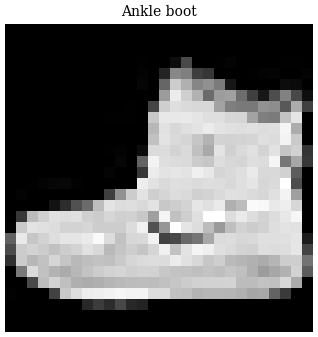

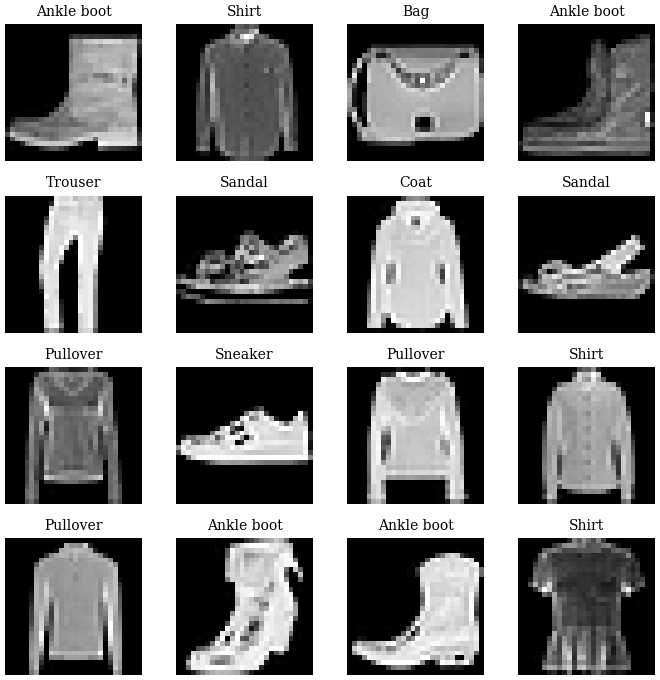

In [3]:
image, label = train_data[0]
plt.imshow(image.squeeze(), cmap="gray"); plt.title(class_names[label]); plt.axis(False); plt.show()
torch.manual_seed(42)
fig = plt.figure(figsize=(7, 7))
rows, cols = 4, 4
for i in range(1, rows * cols + 1):
    random_idx = torch.randint(0, len(train_data), size=[1]).item()
    img, label = train_data[random_idx]
    fig.add_subplot(rows, cols, i)
    plt.imshow(img.squeeze(), cmap="gray"); plt.title(class_names[label]); plt.axis(False)
plt.tight_layout(); plt.show()

## 2. Prepare a DataLoader

A `DataLoader` serves the data in **mini-batches**, here of 32 images, and shuffles the training set every epoch (Week 10's mini-batch gradient descent).

![batching FashionMNIST](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-batching-fashionmnist.png)

*60,000 training images in mini-batches of 32. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-batching-fashionmnist.png) (Daniel Bourke).*

In [4]:
from torch.utils.data import DataLoader
BATCH_SIZE = 32
train_dataloader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True)
test_dataloader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False)
print(f"Length of train dataloader: {len(train_dataloader)} batches of {BATCH_SIZE}")
print(f"Length of test dataloader: {len(test_dataloader)} batches of {BATCH_SIZE}")
train_features_batch, train_labels_batch = next(iter(train_dataloader))
print(train_features_batch.shape, train_labels_batch.shape)

Length of train dataloader: 1875 batches of 32
Length of test dataloader: 313 batches of 32
torch.Size([32, 1, 28, 28]) torch.Size([32])


## 3. Model 0: a baseline

A plain network first, as in Week 10. `nn.Flatten()` turns each `[1, 28, 28]` image into a vector of 784 numbers; two linear layers with 10 units follow.

In [5]:
flatten_model = nn.Flatten()
x = train_features_batch[0]
print(f"Shape before flattening: {x.shape} -> [color_channels, height, width]")
print(f"Shape after flattening: {flatten_model(x).shape} -> [color_channels, height*width]")

class FashionMNISTModelV0(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.Linear(in_features=hidden_units, out_features=output_shape))
    def forward(self, x):
        return self.layer_stack(x)

torch.manual_seed(42)
model_0 = FashionMNISTModelV0(input_shape=784, hidden_units=10, output_shape=len(class_names))
print(model_0)

Shape before flattening: torch.Size([1, 28, 28]) -> [color_channels, height, width]
Shape after flattening: torch.Size([1, 784]) -> [color_channels, height*width]
FashionMNISTModelV0(
  (layer_stack): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=10, bias=True)
    (2): Linear(in_features=10, out_features=10, bias=True)
  )
)


### 3.1 Loss, optimizer, metric, and a timer

In [6]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    return (correct / len(y_pred)) * 100

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.1)

from timeit import default_timer as timer
def print_train_time(start: float, end: float, device=None):
    total_time = end - start
    print(f"Train time on {device}: {total_time:.1f} seconds")
    return total_time

### 3.2 Training on batches

For each epoch, loop through the training batches and take one gradient step per batch (the five steps of Week 10), then loop through the test batches and average the loss and the accuracy. The two loops are written as functions so that every model below reuses them.

In [7]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

def train_step(model, data_loader, loss_fn, optimizer, accuracy_fn, device=device):
    train_loss, train_acc = 0, 0
    model.to(device); model.train()
    for X, y in data_loader:
        X, y = X.to(device), y.to(device)
        y_pred = model(X)                             # 1. forward pass
        loss = loss_fn(y_pred, y)                     # 2. loss
        train_loss += loss.item()
        train_acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
        optimizer.zero_grad()                         # 3. zero the gradients
        loss.backward()                               # 4. backward pass
        optimizer.step()                              # 5. step
    print(f"Train loss: {train_loss / len(data_loader):.5f} | Train accuracy: {train_acc / len(data_loader):.2f}%")

def test_step(model, data_loader, loss_fn, accuracy_fn, device=device):
    test_loss, test_acc = 0, 0
    model.to(device); model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            test_pred = model(X)
            test_loss += loss_fn(test_pred, y).item()
            test_acc += accuracy_fn(y_true=y, y_pred=test_pred.argmax(dim=1))
    print(f"Test loss: {test_loss / len(data_loader):.5f} | Test accuracy: {test_acc / len(data_loader):.2f}%\n")

def eval_model(model, data_loader, loss_fn, accuracy_fn, device=device):
    loss, acc = 0, 0
    model.to(device); model.eval()
    with torch.inference_mode():
        for X, y in data_loader:
            X, y = X.to(device), y.to(device)
            y_pred = model(X)
            loss += loss_fn(y_pred, y).item()
            acc += accuracy_fn(y_true=y, y_pred=y_pred.argmax(dim=1))
    return {"model_name": model.__class__.__name__, "model_loss": loss / len(data_loader), "model_acc": acc / len(data_loader)}

torch.manual_seed(42)
train_time_start = timer()
epochs = 3
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n---------")
    train_step(model_0, train_dataloader, loss_fn, optimizer, accuracy_fn)
    test_step(model_0, test_dataloader, loss_fn, accuracy_fn)
total_train_time_model_0 = print_train_time(train_time_start, timer(), device=device)

device: cpu
Epoch: 0
---------


Train loss: 0.59039 | Train accuracy: 79.17%


Test loss: 0.50954 | Test accuracy: 82.04%

Epoch: 1
---------


Train loss: 0.47633 | Train accuracy: 83.32%


Test loss: 0.47989 | Test accuracy: 83.20%

Epoch: 2
---------


Train loss: 0.45503 | Train accuracy: 84.05%


Test loss: 0.47664 | Test accuracy: 83.43%

Train time on cpu: 11.0 seconds


## 4. Model 0 results

In [8]:
torch.manual_seed(42)
model_0_results = eval_model(model_0, test_dataloader, loss_fn, accuracy_fn)
model_0_results

{'model_name': 'FashionMNISTModelV0',
 'model_loss': 0.47663888325706455,
 'model_acc': 83.42651757188499}

## 5. Model 1: adding non-linearity

The book's next try adds ReLU after each linear layer. Note that it also puts a ReLU after the **last** layer, which cuts every negative score to zero; that removes information the softmax needs, and this model does worse than model 0. Keep it in mind when reading the comparison in section 7.

In [9]:
class FashionMNISTModelV1(nn.Module):
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.layer_stack = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=input_shape, out_features=hidden_units),
            nn.ReLU(),
            nn.Linear(in_features=hidden_units, out_features=output_shape),
            nn.ReLU())
    def forward(self, x: torch.Tensor):
        return self.layer_stack(x)

torch.manual_seed(42)
model_1 = FashionMNISTModelV1(input_shape=784, hidden_units=10, output_shape=len(class_names)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_1.parameters(), lr=0.1)
torch.manual_seed(42)
train_time_start = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n---------")
    train_step(model_1, train_dataloader, loss_fn, optimizer, accuracy_fn)
    test_step(model_1, test_dataloader, loss_fn, accuracy_fn)
total_train_time_model_1 = print_train_time(train_time_start, timer(), device=device)
torch.manual_seed(42)
model_1_results = eval_model(model_1, test_dataloader, loss_fn, accuracy_fn)
model_1_results

Epoch: 0
---------


Train loss: 1.09199 | Train accuracy: 61.34%


Test loss: 0.95637 | Test accuracy: 65.00%

Epoch: 1
---------


Train loss: 0.78101 | Train accuracy: 71.93%


Test loss: 0.72227 | Test accuracy: 73.91%

Epoch: 2
---------


Train loss: 0.67027 | Train accuracy: 75.94%


Test loss: 0.68500 | Test accuracy: 75.02%

Train time on cpu: 11.2 seconds


{'model_name': 'FashionMNISTModelV1',
 'model_loss': 0.6850009507264573,
 'model_acc': 75.01996805111821}

## 6. Model 2: a convolutional neural network (CNN)

A CNN does not flatten the image at the start. Its **convolutional layers** slide small filters over the image and keep the 2-dimensional layout, **pooling layers** shrink the maps, and only at the end does a linear layer classify. The architecture below copies **TinyVGG** from the interactive [CNN Explainer](https://poloclub.github.io/cnn-explainer/) website: two blocks of (convolution, ReLU, convolution, ReLU, max-pooling), then a classifier.

![the TinyVGG architecture in CNN Explainer](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-cnn-explainer-model.png)

*TinyVGG in CNN Explainer, with the feature maps of each layer. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-cnn-explainer-model.png) (Daniel Bourke).*

In [10]:
class FashionMNISTModelV2(nn.Module):
    # TinyVGG, from https://poloclub.github.io/cnn-explainer/
    def __init__(self, input_shape: int, hidden_units: int, output_shape: int):
        super().__init__()
        self.block_1 = nn.Sequential(
            nn.Conv2d(in_channels=input_shape, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.Conv2d(in_channels=hidden_units, out_channels=hidden_units, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2))
        self.block_2 = nn.Sequential(
            nn.Conv2d(hidden_units, hidden_units, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(hidden_units, hidden_units, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2))
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(in_features=hidden_units * 7 * 7, out_features=output_shape))   # 28 -> 14 -> 7 after two poolings
    def forward(self, x: torch.Tensor):
        x = self.block_1(x)
        x = self.block_2(x)
        x = self.classifier(x)
        return x

torch.manual_seed(42)
model_2 = FashionMNISTModelV2(input_shape=1, hidden_units=10, output_shape=len(class_names)).to(device)
print(model_2)
x = torch.rand(1, 1, 28, 28).to(device)
for name, layer in [("input", None), ("block_1", model_2.block_1), ("block_2", model_2.block_2), ("classifier", model_2.classifier)]:
    if layer is not None:
        x = layer(x)
    print(f"{name:10s} -> {tuple(x.shape)}")

FashionMNISTModelV2(
  (block_1): Sequential(
    (0): Conv2d(1, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block_2): Sequential(
    (0): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(10, 10, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU()
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=490, out_features=10, bias=True)
  )
)
input      -> (1, 1, 28, 28)
block_1    -> (1, 10, 14, 14)
block_2    -> (1, 10, 7, 7)
classifier -> (1, 10)


### 6.1 Stepping through `nn.Conv2d()`

A batch of 32 random "colour images" of 64 × 64 pixels shows what a convolutional layer does to shapes. Its settings:

| setting | meaning |
|---|---|
| `in_channels` | channels of the input (3 for colour) |
| `out_channels` | number of filters, so number of feature maps produced |
| `kernel_size` | size of each filter, 3 means 3 × 3 |
| `stride` | how many pixels the filter moves per step |
| `padding` | how many rings of zeros are added around the image |

![animation of a 2D convolution](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-conv2d-layer.gif)

*A 3 × 3 filter slides over the input, and each position gives one number of the output map. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-conv2d-layer.gif) (Daniel Bourke).*

In [11]:
torch.manual_seed(42)
images = torch.randn(size=(32, 3, 64, 64))       # [batch_size, color_channels, height, width]
test_image = images[0]
print(f"Image batch shape: {images.shape}\nSingle image shape: {test_image.shape}")
torch.manual_seed(42)
conv_layer = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=3, stride=1, padding=0)
print("kernel 3, stride 1, padding 0:", conv_layer(test_image.unsqueeze(dim=0)).shape)
torch.manual_seed(42)
conv_layer_2 = nn.Conv2d(in_channels=3, out_channels=10, kernel_size=(5, 5), stride=2, padding=0)
print("kernel 5, stride 2, padding 0:", conv_layer_2(test_image.unsqueeze(dim=0)).shape)
print(f"conv_layer_2 weight shape: {conv_layer_2.weight.shape} -> [out_channels=10, in_channels=3, kernel_size=5, kernel_size=5]")
print(f"conv_layer_2 bias shape: {conv_layer_2.bias.shape} -> [out_channels=10]")

Image batch shape: torch.Size([32, 3, 64, 64])
Single image shape: torch.Size([3, 64, 64])
kernel 3, stride 1, padding 0: torch.Size([1, 10, 62, 62])
kernel 5, stride 2, padding 0: torch.Size([1, 10, 30, 30])
conv_layer_2 weight shape: torch.Size([10, 3, 5, 5]) -> [out_channels=10, in_channels=3, kernel_size=5, kernel_size=5]
conv_layer_2 bias shape: torch.Size([10]) -> [out_channels=10]


The output size follows one formula. For an input of $n \times n$ pixels, a $k \times k$ filter, padding $p$ and stride $s$, each side of the output has

$$ \left\lfloor \frac{n + 2p - k}{s} \right\rfloor + 1 $$

pixels: $64$ with $k = 3$, $p = 0$, $s = 1$ gives $62$; with $k = 5$, $s = 2$ it gives $\lfloor 59/2 \rfloor + 1 = 30$; TinyVGG's $28$ with $k = 3$, $p = 1$ stays $28$.

In [12]:
out = lambda n, k, p, s: (n + 2 * p - k) // s + 1
print(out(64, 3, 0, 1), out(64, 5, 0, 2), out(28, 3, 1, 1), out(224, 3, 0, 1))

62 30 28 222


### 6.2 Stepping through `nn.MaxPool2d()`

Max pooling with a $2 \times 2$ window keeps the largest of each four neighbouring numbers, which halves the height and the width and keeps the strongest responses. It has no parameters.

In [13]:
max_pool_layer = nn.MaxPool2d(kernel_size=2)
test_image_through_conv = conv_layer(test_image.unsqueeze(dim=0))
print(f"Shape after conv_layer(): {test_image_through_conv.shape}")
print(f"Shape after conv_layer() and max_pool_layer(): {max_pool_layer(test_image_through_conv).shape}")
torch.manual_seed(42)
random_tensor = torch.randn(size=(1, 1, 2, 2))
print(f"Random tensor:\n{random_tensor}\nMax pool tensor: {max_pool_layer(random_tensor)} <- the largest value")

Shape after conv_layer(): torch.Size([1, 10, 62, 62])
Shape after conv_layer() and max_pool_layer(): torch.Size([1, 10, 31, 31])
Random tensor:
tensor([[[[0.3367, 0.1288],
          [0.2345, 0.2303]]]])
Max pool tensor: tensor([[[[0.3367]]]]) <- the largest value


![a CNN compresses an image](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-conv-net-as-compression.png)

*Each block makes the representation smaller and more abstract, until a linear layer can classify it. Figure from [Learn PyTorch for Deep Learning](https://raw.githubusercontent.com/mrdbourke/pytorch-deep-learning/main/images/03-conv-net-as-compression.png) (Daniel Bourke).*

### 6.3 Loss and optimizer for model 2

In [14]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model_2.parameters(), lr=0.1)

### 6.4 Training and testing model 2

In [15]:
torch.manual_seed(42)
train_time_start = timer()
for epoch in range(epochs):
    print(f"Epoch: {epoch}\n---------")
    train_step(model_2, train_dataloader, loss_fn, optimizer, accuracy_fn)
    test_step(model_2, test_dataloader, loss_fn, accuracy_fn)
total_train_time_model_2 = print_train_time(train_time_start, timer(), device=device)
torch.manual_seed(42)
model_2_results = eval_model(model_2, test_dataloader, loss_fn, accuracy_fn)
model_2_results

Epoch: 0
---------


Train loss: 0.59535 | Train accuracy: 78.34%


Test loss: 0.39035 | Test accuracy: 85.99%

Epoch: 1
---------


Train loss: 0.36313 | Train accuracy: 86.85%


Test loss: 0.35447 | Test accuracy: 86.81%

Epoch: 2
---------


Train loss: 0.32489 | Train accuracy: 88.33%


Test loss: 0.32741 | Test accuracy: 87.81%

Train time on cpu: 69.5 seconds


{'model_name': 'FashionMNISTModelV2',
 'model_loss': 0.32740892410373534,
 'model_acc': 87.80950479233226}

## 7. Compare model results and training time

            model_name  model_loss  model_acc  parameters  training_time
0  FashionMNISTModelV0       0.477     83.427        7960          10.99
1  FashionMNISTModelV1       0.685     75.020        7960          11.19
2  FashionMNISTModelV2       0.327     87.810        7740          69.53


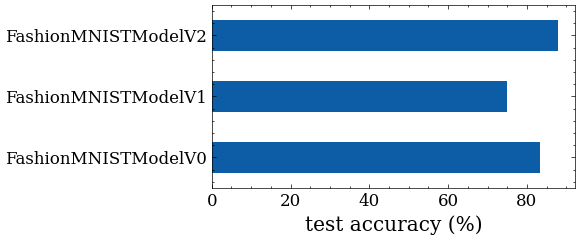

In [16]:
n_params = lambda m: sum(p.numel() for p in m.parameters())
compare_results = pd.DataFrame([model_0_results, model_1_results, model_2_results])
compare_results["parameters"] = [n_params(model_0), n_params(model_1), n_params(model_2)]
compare_results["training_time"] = [total_train_time_model_0, total_train_time_model_1, total_train_time_model_2]
print(compare_results.round(3))
compare_results.set_index("model_name")["model_acc"].plot(kind="barh", figsize=(6, 2.6))
plt.xlabel("test accuracy (%)"); plt.ylabel(""); plt.tight_layout(); plt.show()

The CNN reaches the highest test accuracy with fewer parameters than model 0 (7,740 against 7,960), and it takes longer to train: every filter is applied at every position of the image. Its exact accuracy (about 88%) changes by a few tenths of a percent from run to run and machine to machine; the book reports 88.4%.

## 8. Random predictions with the best model

predictions: [5, 1, 7, 4, 3, 0, 4, 7, 1] 
truth:       [5, 1, 7, 4, 3, 0, 4, 7, 1]


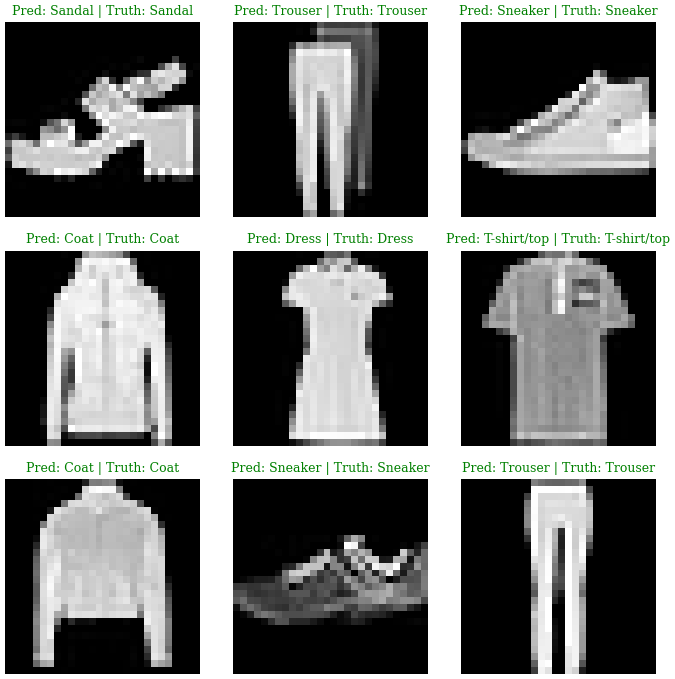

In [17]:
def make_predictions(model, data, device=device):
    pred_probs = []
    model.eval()
    with torch.inference_mode():
        for sample in data:
            sample = torch.unsqueeze(sample, dim=0).to(device)
            pred_logit = model(sample)
            pred_probs.append(torch.softmax(pred_logit.squeeze(), dim=0).cpu())
    return torch.stack(pred_probs)

import random
random.seed(42)
test_samples, test_labels = [], []
for sample, label in random.sample(list(test_data), k=9):
    test_samples.append(sample); test_labels.append(label)
pred_probs = make_predictions(model_2, test_samples)
pred_classes = pred_probs.argmax(dim=1)
print("predictions:", pred_classes.tolist(), "\ntruth:      ", test_labels)
plt.figure(figsize=(7, 7))
for i, sample in enumerate(test_samples):
    plt.subplot(3, 3, i + 1)
    plt.imshow(sample.squeeze(), cmap="gray")
    pred_label, truth_label = class_names[pred_classes[i]], class_names[test_labels[i]]
    plt.title(f"Pred: {pred_label} | Truth: {truth_label}", fontsize=9, c="g" if pred_label == truth_label else "r")
    plt.axis(False)
plt.tight_layout(); plt.show()

## 9. A confusion matrix

Week 9's confusion matrix shows which classes are mixed up. (The book uses `torchmetrics` and `mlxtend`; scikit-learn's version needs no extra install.)

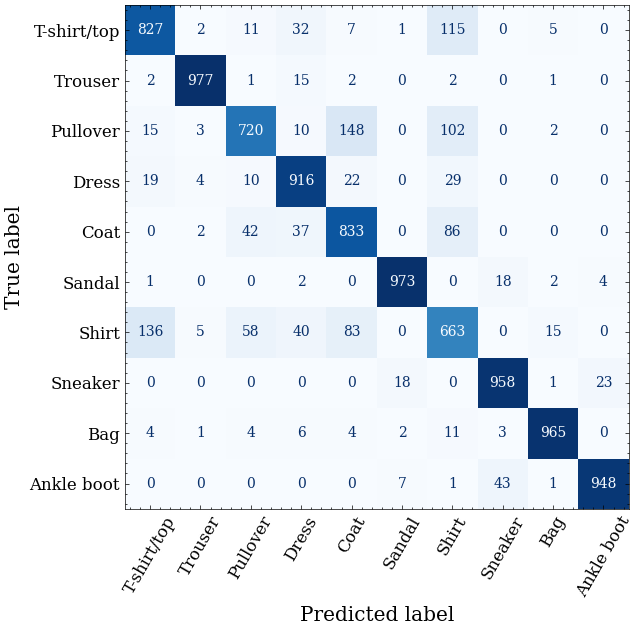

largest confusions (count, true, predicted): [(148, 'Pullover', 'Coat'), (136, 'Shirt', 'T-shirt/top'), (115, 'T-shirt/top', 'Shirt'), (102, 'Pullover', 'Shirt')]


In [18]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_preds = []
model_2.eval()
with torch.inference_mode():
    for X, y in test_dataloader:
        y_preds.append(model_2(X.to(device)).argmax(dim=1).cpu())
y_pred_tensor = torch.cat(y_preds)
cm = confusion_matrix(test_data.targets, y_pred_tensor)
fig, ax = plt.subplots(figsize=(7, 6.5))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=60)
plt.tight_layout(); plt.show()
off = [(int(cm[i, j]), class_names[i], class_names[j]) for i in range(10) for j in range(10) if i != j]
print("largest confusions (count, true, predicted):", sorted(off, reverse=True)[:4])

## 10. Save and load the best model

In [19]:
from pathlib import Path
MODEL_PATH = Path("models"); MODEL_PATH.mkdir(parents=True, exist_ok=True)
MODEL_SAVE_PATH = MODEL_PATH / "03_pytorch_computer_vision_model_2.pth"
print(f"Saving model to: {MODEL_SAVE_PATH}")
torch.save(obj=model_2.state_dict(), f=MODEL_SAVE_PATH)
torch.manual_seed(42)
loaded_model_2 = FashionMNISTModelV2(input_shape=1, hidden_units=10, output_shape=10)
loaded_model_2.load_state_dict(torch.load(f=MODEL_SAVE_PATH))
loaded_model_2 = loaded_model_2.to(device)
torch.manual_seed(42)
loaded_model_2_results = eval_model(loaded_model_2, test_dataloader, loss_fn, accuracy_fn)
print(loaded_model_2_results)
print("same results:", torch.isclose(torch.tensor(model_2_results["model_loss"]), torch.tensor(loaded_model_2_results["model_loss"]), atol=1e-02).item())

Saving model to: models/03_pytorch_computer_vision_model_2.pth


{'model_name': 'FashionMNISTModelV2', 'model_loss': 0.32740892410373534, 'model_acc': 87.80950479233226}
same results: True


## 11. Inside the CNN

### 11.1 A convolution by hand

A filter is a small grid of weights. At each position, multiply the filter with the image patch under it entry by entry and add up the products. The vertical-edge filter below responds where the image gets brighter from left to right.

by hand: 27.0
nn.Conv2d with these weights: 27.0


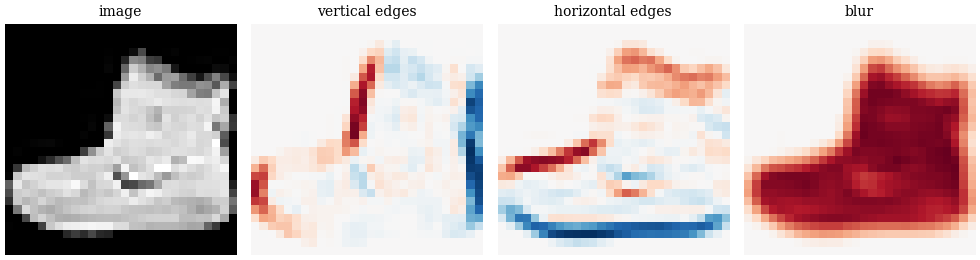

In [20]:
patch = torch.tensor([[0., 0., 9.],
                      [0., 0., 9.],
                      [0., 0., 9.]])
kernel = torch.tensor([[-1., 0., 1.],
                       [-1., 0., 1.],
                       [-1., 0., 1.]])
print("by hand:", (patch * kernel).sum().item())
conv = nn.Conv2d(1, 1, kernel_size=3, bias=False)
with torch.no_grad():
    conv.weight[:] = kernel
print("nn.Conv2d with these weights:", conv(patch[None, None]).item())

boot = train_data[0][0]                             # an ankle boot, shape [1, 28, 28]
kernels = {"vertical edges": kernel, "horizontal edges": kernel.T, "blur": torch.ones(3, 3) / 9}
fig, ax = plt.subplots(1, 4, figsize=(10, 2.8))
ax[0].imshow(boot.squeeze(), cmap="gray"); ax[0].set_title("image"); ax[0].axis(False)
for a, (name, k) in zip(ax[1:], kernels.items()):
    fmap = nn.functional.conv2d(boot[None], k[None, None], padding=1)[0, 0]
    a.imshow(fmap, cmap="RdBu_r", vmin=-fmap.abs().max(), vmax=fmap.abs().max()); a.set_title(name); a.axis(False)
plt.tight_layout(); plt.show()

### 11.2 What the trained CNN's first layer sees

The 10 filters of model 2's first convolutional layer were learned by backpropagation, nobody set them by hand. Their feature maps on one image show what each responds to: edges in different directions, bright or dark areas.

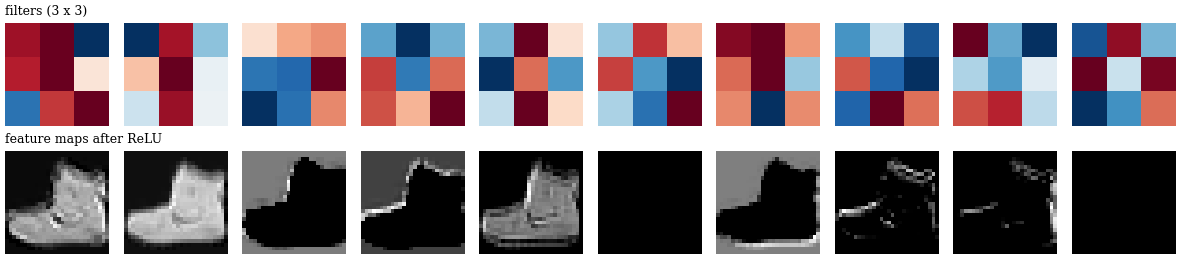

In [21]:
model_2.eval()
with torch.inference_mode():
    fmaps = model_2.block_1[1](model_2.block_1[0](boot[None].to(device)))[0].cpu()
w = model_2.block_1[0].weight.detach().cpu()
fig, ax = plt.subplots(2, 10, figsize=(12, 2.8))
for i in range(10):
    ax[0, i].imshow(w[i, 0], cmap="RdBu_r"); ax[0, i].axis(False)
    ax[1, i].imshow(fmaps[i], cmap="gray"); ax[1, i].axis(False)
ax[0, 0].set_title("filters (3 x 3)", loc="left", fontsize=9); ax[1, 0].set_title("feature maps after ReLU", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

### 11.3 Data augmentation

With few training images, a network can learn new copies made by small changes that keep the label: flips, small rotations, crops, brightness. `torchvision.transforms` applies them at random, so each epoch sees slightly different versions.

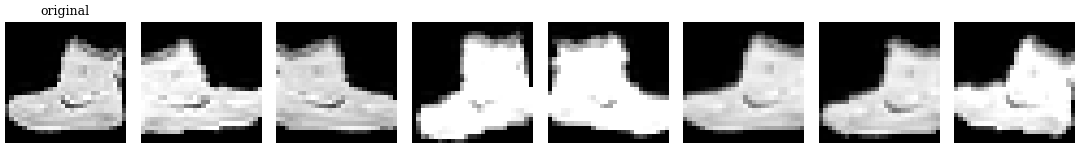

an augmented training set only needs a different transform: torch.Size([1, 28, 28])


In [22]:
from torchvision import transforms
augment = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.RandomResizedCrop(size=28, scale=(0.8, 1.0)),
    transforms.ColorJitter(brightness=0.4)])
torch.manual_seed(0)
fig, ax = plt.subplots(1, 8, figsize=(11, 1.8))
ax[0].imshow(boot.squeeze(), cmap="gray"); ax[0].set_title("original", fontsize=9)
for a in ax[1:]:
    a.imshow(augment(boot).squeeze(), cmap="gray")
for a in ax: a.axis(False)
plt.tight_layout(); plt.show()
train_data_augmented = datasets.FashionMNIST(root="data", train=True, download=True, transform=transforms.Compose([ToTensor(), augment]))
print("an augmented training set only needs a different transform:", train_data_augmented[0][0].shape)

### 11.4 Rare classes

Suppose only 1% of the images were bags and the task were "bag or not". A model that always says "not a bag" is right 99% of the time and finds no bag, so accuracy alone says little (Week 9). Common remedies:

- make more copies of the rare class (augmentation) or use fewer of the common one (undersampling);
- weight the loss, so that a mistake on the rare class costs more;
- start the output bias at $\ln(\text{pos}/\text{neg})$, so that the untrained network already predicts the base rate $\sigma(b) = \text{pos}/(\text{pos} + \text{neg})$;
- judge the model by the confusion matrix, precision and recall instead of accuracy.

In [23]:
is_bag = (test_data.targets == class_names.index("Bag"))
rng = np.random.default_rng(0)
keep = np.where(~is_bag.numpy() | (rng.random(len(is_bag)) < 0.1))[0]     # keep about 10% of the bags
y_rare = is_bag[keep].int()
pos, neg = int(y_rare.sum()), int((1 - y_rare).sum())
print(f"{pos} bags among {pos + neg} images: always saying 'not a bag' is right {100 * neg / (pos + neg):.1f}% of the time")
b0 = np.log(pos / neg)
print(f"initial bias ln(pos/neg) = {b0:.3f}, so the untrained output sigmoid(b0) = {1 / (1 + np.exp(-b0)):.4f} = pos/(pos+neg) = {pos / (pos + neg):.4f}")
weighted_loss = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(neg / pos))
print("a weighted loss: each bag counts", round(neg / pos, 1), "times")

107 bags among 9107 images: always saying 'not a bag' is right 98.8% of the time
initial bias ln(pos/neg) = -4.432, so the untrained output sigmoid(b0) = 0.0117 = pos/(pos+neg) = 0.0117
a weighted loss: each bag counts 84.1 times


### 11.5 Pretrained networks

Large CNNs trained on millions of photos are available in `torchvision.models`. **ResNet-18**, for example, has 11.7 million parameters and was trained on ImageNet, 1.2 million photos in 1,000 classes. Its early layers detect edges, textures and shapes useful for almost any photo, so a new task can reuse them and train only a new last layer; this is **transfer learning**. (Downloading the pretrained weights takes 45 MB; the cell below builds the network without them, to show its size.)

In [24]:
resnet = torchvision.models.resnet18(weights=None)          # weights="IMAGENET1K_V1" downloads the trained weights
print(f"ResNet-18 parameters: {n_params(resnet):,}")
print("its last layer:", resnet.fc)
resnet.fc = nn.Linear(resnet.fc.in_features, 2)                # a new last layer for a two-class task
for p in resnet.parameters():
    p.requires_grad = False
for p in resnet.fc.parameters():
    p.requires_grad = True                                     # train only the new layer
print(f"trainable parameters: {sum(p.numel() for p in resnet.parameters() if p.requires_grad):,}")

ResNet-18 parameters: 11,689,512
its last layer: Linear(in_features=512, out_features=1000, bias=True)
trainable parameters: 1,026


## Practice exercises

**These are practice for yourself, and they are not the graded assignments.** Problem sets are released separately on Blackboard, with due dates. Exercises 1–5 follow the book's exercises for chapter 03.

1. **CNN Explainer.** Spend 20 minutes on the [CNN Explainer](https://poloclub.github.io/cnn-explainer/) website. Upload your own image and follow it through each layer.
2. **MNIST.** Load the handwritten digits of `torchvision.datasets.MNIST`, show five samples, and make DataLoaders with batch size 32.
3. **TinyVGG on MNIST.** Recreate `model_2` for MNIST, train it for 3 epochs, and plot five predictions with their true labels.
4. **Confusion matrix.** Plot the confusion matrix of your MNIST model. Which digits are confused most?
5. **Shapes.** Create a random tensor of shape `[1, 3, 64, 64]` and pass it through `nn.Conv2d` layers with different `kernel_size`, `stride` and `padding`. Check each output size against the formula of section 6.1.
6. **Fix model 1.** Remove the final ReLU of `FashionMNISTModelV1` and retrain. Does it now beat model 0?
7. **Wider CNN.** Train `model_2` with `hidden_units=32`. How do the test accuracy, the number of parameters and the training time change?
